# Zadanie 1 — PenDigits

**Cel:** poznaj numeryczny zbiór danych, porównaj kilka uzasadnionych metod klasyfikacji statystycznej i uczenia maszynowego oraz oceń, czy większa złożoność modelu daje istotną korzyść.

In [1]:
# Proponowane importy — możesz je zmienić lub rozszerzyć.
from pathlib import Path
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from huggingface_hub import hf_hub_download
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

In [2]:
# Pobranie niezmienionego archiwum z oficjalnymi podziałami train/test.
DATA_DIR = Path("data/zadanie-1")
DATA_DIR.mkdir(parents=True, exist_ok=True)

archive_path = hf_hub_download(
    repo_id="AI-MED-AGH/Recruitment-Task-1",
    filename="original/pen+based+recognition+of+handwritten+digits.zip",
    repo_type="dataset",
    local_dir=DATA_DIR,
)
with ZipFile(archive_path) as archive:
    archive.extractall(DATA_DIR / "pendigits")

print(f"Dane zapisano w: {DATA_DIR / 'pendigits'}")

original/pen+based+recognition+of+handwr(…): reconstructing file:   0%|          |  0.00B / 1.67MB            

original/pen+based+recognition+of+handwr(…): downloading bytes:           |  0.00B            

Dane zapisano w: data\zadanie-1\pendigits


## A — Poznanie i przygotowanie danych

Rozpoznaj zmienną docelową i cechy, sprawdź rozkład klas, braki, duplikaty oraz zakresy wartości. Pokaż krótką eksplorację danych i uzasadnij preprocessing. Zachowaj oficjalny podział danych; nie zastępuj go losowym podziałem.

In [19]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [60]:
cols = [f"{axis}{i}" for i in range(1, 9) for axis in ("x", "y")] + ["digit"]

train_df = pd.read_csv("data/zadanie-1/pendigits/pendigits.tra", header=None, names=cols)
test_df = pd.read_csv("data/zadanie-1/pendigits/pendigits.tes", header=None, names=cols)

print(f"shape: {train_df.shape}, {test_df.shape}\n")
print(train_df.describe().T)
print()
print(f'digits: {train_df["digit"].value_counts().sort_index().to_frame().T}')

shape: (7494, 17), (3498, 17)

        count       mean        std  min   25%   50%    75%    max
x1     7494.0  37.384307  33.322024  0.0   5.0  31.0   61.0  100.0
y1     7494.0  84.679343  16.848420  0.0  76.0  89.0  100.0  100.0
x2     7494.0  40.005604  26.256025  0.0  20.0  39.0   58.0  100.0
y2     7494.0  82.889512  19.638582  0.0  70.0  89.0  100.0  100.0
x3     7494.0  50.878303  34.927201  0.0  17.0  56.0   81.0  100.0
y3     7494.0  65.044436  27.377341  0.0  48.0  71.0   86.0  100.0
x4     7494.0  51.471844  30.680075  0.0  28.0  54.0   75.0  100.0
y4     7494.0  44.599680  30.659478  0.0  22.0  42.0   65.0  100.0
x5     7494.0  57.129971  33.680340  0.0  30.0  60.0   88.0  100.0
y5     7494.0  34.069122  27.459989  0.0   7.0  33.0   55.0  100.0
x6     7494.0  61.417401  37.130762  0.0  25.0  74.0   98.0  100.0
y6     7494.0  35.782092  27.495836  0.0  12.0  32.0   57.0  100.0
x7     7494.0  54.699760  22.599781  0.0  41.0  53.0   69.0  100.0
y7     7494.0  35.800774  33.22

In [68]:
missing_training_data = train_df.isna().sum().to_frame().T
print(missing_training_data)

#checking test set for safty
missing_testing_data = test_df.isna().sum().to_frame().T
print(missing_testing_data)

# checking if smth from train set leaked into test set
leaked = pd.merge(train_df, test_df)

print(f"duplicates: {train_df.duplicated().sum()}")
print(f"leaked: {len(leaked)}")

   x1  y1  x2  y2  x3  y3  x4  y4  x5  y5  x6  y6  x7  y7  x8  y8  digit
0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0      0
   x1  y1  x2  y2  x3  y3  x4  y4  x5  y5  x6  y6  x7  y7  x8  y8  digit
0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0      0
duplicates: 0
leaked: 0


In [ ]:
def visualize(sample: np.ndarray):
    x = sample[:16:2]
    y = sample[1:16:2]

    fig, ax = plt.subplots()
    ax.plot(x, y, color="red", linestyle="-", marker="o")
    ax.set_title(f"{sample[16]}")
    ax.axis("off")
    plt.show()
visualize(train_df.iloc[5].to_numpy())
    

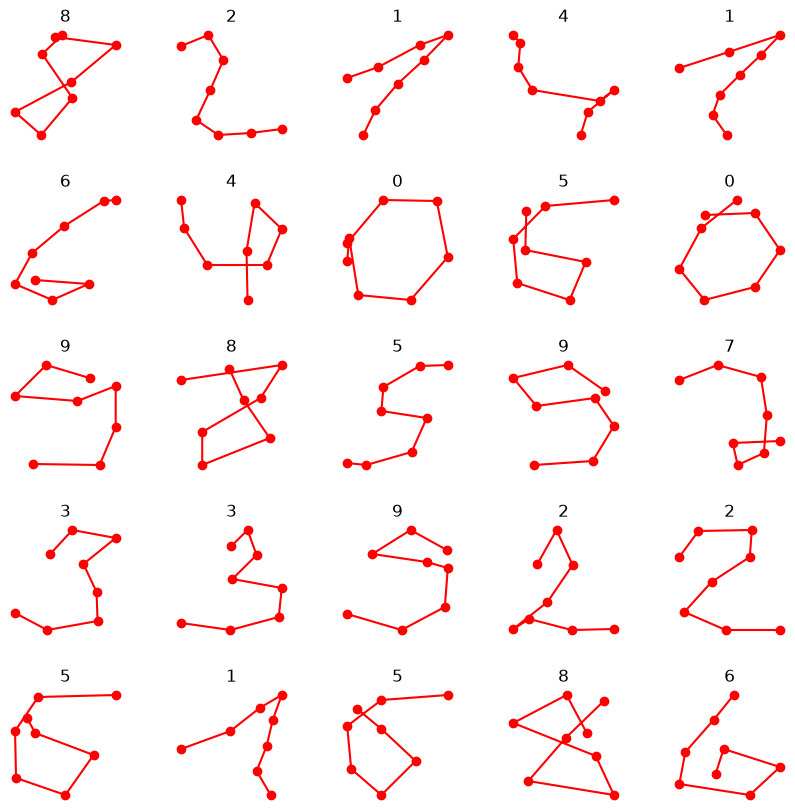

In [67]:
n = 5; m = 5;
fig, ax = plt.subplots(n, m, figsize=(10, 10))
for i in range(n * m):
    sample = train_df.iloc[i].to_numpy()
    x = sample[:16:2]
    y = sample[1:16:2]

    ax[i//m][i%m].plot(x, y, color="red", linestyle="-", marker="o")
    ax[i//m][i%m].set_title(f"{sample[16]}")
    ax[i//m][i%m].axis("off")

plt.subplots_adjust(wspace=0.5,hspace=0.5)
plt.show()

# Wnioski:
Celem jest przewidzenie, jaką cyfrę tworzą punkty. Zbiór ma 10 klas o zbliżonej liczności, więc nie ma potrzeby stratyfikowania foldów w walidacji krzyżowej.

Analiza danych wykazała, że:
- wszystkie wartości są typu int z przedziału 0-100
- nie ma braków danych
- żaden wiersz nie występuje jednocześnie w zbiorze treningowym i testowym

Modelem bazowym będzie regresja logistyczna z regularyzacją L2. Ponieważ jest ona wrażliwa na skalę cech, zastosuję MinMaxScaler wewnątrz Pipeline. Następnie sprawdzę Random Forest, który nie wymaga preprocessingu, bo jest niewrażliwy na skalę cech, a dobrze radzi sobie z zależnościami nieliniowymi. Na końcu przetestuję hipotezę, że kolejność punktów przy pisaniu cyfry niesie dodatkową informację. Sprawdzę to dodając cechy pochodne lub wykorzystując modele uwzględniające sekwencję.

In [ ]:
# Preprocessing
from sklearn.preprocessing import MinMaxScaler

X_train, y_train = train_df.drop(columns="digit"), train_df["digit"]
X_test, y_test = test_df.drop(columns="digit"), test_df["digit"]

preprocess = Pipeline([
    ("scaler", MinMaxScaler()),
])

X_train = preprocess.fit_transform(X_train)
X_test = preprocess.transform(X_test)


## B — Modelowanie

Zbuduj prosty model bazowy i porównaj go z kilkoma klasyfikatorami statystycznymi lub klasycznego uczenia maszynowego. Wykonaj dobór modeli, strojenie i sposób zapobiegania wyciekowi danych. 

## C — Porównanie i wnioski

Porównaj modele na oficjalnym zbiorze testowym za pomocą odpowiednich metryk liczbowych. Uwzględnij błędy oraz praktyczny koszt modeli, np. czas uczenia i inferencji albo liczbę parametrów. Odpowiedz, czy wzrost złożoności jest wart uzyskanej poprawy.

## Oddanie zadania

Zapisz kod, wyniki, wykresy i krótkie uzasadnienia w tym notatniku. Podaj użyte źródła oraz narzędzia AI i upewnij się, że notatnik można uruchomić od początku do końca. Wykonaj commit po zakończeniu zadania aby znalazł się na repozytorium.